Tự viết K‐Means

In [2]:
# -*- coding: utf-8 -*-
"""Bước 1: tự viết K-Means bằng numpy, chạy trên bảy điểm của slide.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
from sklearn.cluster import KMeans

P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vao tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0)
                            for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan

# Khởi tạo cố ý tệ: hai tâm là A và B, nằm sát nhau
tam, nhan = k_means(P, P[[0, 1]].copy())
print()

# Tính inertia: tổng bình phương khoảng cách tới tâm cụm của mình
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

# So với scikit-learn, cho cùng tâm ban đầu
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


Phân khúc khách hàng

In [4]:
# -*- coding: utf-8 -*-
"""Bước 2: phân khúc khách hàng bằng K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()
print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0],
                    "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
          f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


Chọn số cụm K

In [7]:
# -*- coding: utf-8 -*-
"""Bước 3: chọn số cụm K bằng khuỷu tay và chỉ số silhouette."""

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print(" K  inertia  giam so voi K-1  silhouette")
truoc = None
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    # Silhouette cần ít nhất hai cụm
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f" {k:2d} {km.inertia_:7.1f} {giam:>15s} {sil:>10s}")
    truoc = km.inertia_

 K  inertia  giam so voi K-1  silhouette
  1   420.0                           
  2   250.4           169.6      0.430
  3   152.5            97.9      0.522
  4    73.8            78.8      0.626
  5    23.0            50.7      0.723
  6    20.9             2.1      0.651
  7    19.0             1.9      0.541
  8    17.4             1.6      0.454
  9    15.9             1.5      0.471
 10    14.4             1.4      0.425


Ba cái bẫy của K‐Means

In [9]:
# -*- coding: utf-8 -*-
"""Bước 4: ba cái bẫy của K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000 # đổi lại triệu đồng để dễ đọc
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1,
                random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
# Số thứ tự cụm có thể ngược với nhãn thật, nên lấy cách khớp tốt hơn
print(f"Bay 3: hai vang trang, ty le khop nhan that "
      f"{max(khop, 1 - khop):.4f}")

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  52.5)
  (  9.6,  41.9)
  ( 17.4,  49.8)
  ( 27.8,  52.9)
  ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


Nén màu ảnh

In [11]:
# -*- coding: utf-8 -*-
"""Bước 5: nén màu một bức ảnh bằng K-Means."""

import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

anh = load_sample_image("china.jpg") # ảnh có sẵn trong scikit-learn
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0 # mỗi dòng là một điểm ảnh RGB
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

# Học trên 5000 điểm ảnh rút ngẫu nhiên cho nhanh, rồi gán cho mọi điểm
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print(" K so bit moi diem nho hon sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f" {k:2d} {bit} {24 / bit:4.1f} lan"
          f" {sai:5.2f} muc sang")

Anh 427 x 640, co 273280 diem anh, 96615 mau

 K so bit moi diem nho hon sai lech trung binh
  4 2 12.0 lan 17.41 muc sang
 16 4  6.0 lan  7.97 muc sang
 64 6  4.0 lan  4.54 muc sang


Bài tập thực hành

In [14]:
#bài 1
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]].to_numpy(dtype=float)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=0
)
nhan = kmeans.fit_predict(X_scaled)
def silhouette_mot_diem(X, nhan, i):
    nhan_diem = nhan[i]
    # Cac diem khac trong cung cum
    cung_cum = np.where(nhan == nhan_diem)[0]
    cung_cum = cung_cum[cung_cum != i]
    # Neu cum chi co mot diem thi Silhouette bang 0
    if len(cung_cum) == 0:
        return 0.0, 0.0, 0.0
    # a: khoang cach trung binh den cac diem cung cum
    khoang_cach_a = np.linalg.norm(
        X[cung_cum] - X[i],
        axis=1
    )
    a = khoang_cach_a.mean()
    # b: khoang cach trung binh nho nhat den cum khac
    khoang_cach_cum_khac = []
    for cum_khac in np.unique(nhan):
        if cum_khac != nhan_diem:
            diem_cum_khac = X[nhan == cum_khac]
            khoang_cach = np.linalg.norm(
                diem_cum_khac - X[i],
                axis=1
            )
            khoang_cach_cum_khac.append(
                khoang_cach.mean()
            )
    b = min(khoang_cach_cum_khac)
    # s: gia tri Silhouette
    s = (b - a) / max(a, b)
    return a, b, s
# Tinh Silhouette cho tat ca khach hang
danh_sach_s = []
for i in range(len(X_scaled)):
    a, b, s = silhouette_mot_diem(
        X_scaled,
        nhan,
        i
    )
    danh_sach_s.append(s)
danh_sach_s = np.array(danh_sach_s)
# Silhouette trung binh tu ham tu viet
silhouette_tu_viet = danh_sach_s.mean()
# Silhouette trung binh bang sklearn
silhouette_sklearn = silhouette_score(
    X_scaled,
    nhan
)
# Tim khach hang co Silhouette nho nhat
vi_tri_nho_nhat = np.argmin(danh_sach_s)

print("Silhouette tu viet:", round(silhouette_tu_viet, 6))
print("Silhouette sklearn:", round(silhouette_sklearn, 6))
print("\nKhach hang co Silhouette nho nhat:")
print("So thu tu:", vi_tri_nho_nhat + 1)
print("Gia tri Silhouette:", round(danh_sach_s[vi_tri_nho_nhat], 6))
print("\nThong tin khach hang:")
print(df.iloc[vi_tri_nho_nhat])
print("\nToa do tren Hinh 3:")
print("Thu nhap:", X[vi_tri_nho_nhat, 0])
print("Diem chi tieu:", X[vi_tri_nho_nhat, 1])


Silhouette tu viet: 0.722706
Silhouette sklearn: 0.722706

Khach hang co Silhouette nho nhat:
So thu tu: 114
Gia tri Silhouette: 0.028571

Thong tin khach hang:
tuoi             38.0
thu_nhap         25.4
diem_chi_tieu    41.0
Name: 113, dtype: float64

Toa do tren Hinh 3:
Thu nhap: 25.4
Diem chi tieu: 41.0


Nhận xét:
- a là khoảng cách trung bình từ một điểm đến các điểm còn lại trong cùng cụm. a càng nhỏ thì điểm đó càng gần các điểm thuộc cụm của mình.
- b là khoảng cách trung bình nhỏ nhất từ điểm đang xét đến các điểm thuộc một cụm khác. b càng lớn thì điểm càng cách xa cụm khác.
- Công thức Silhouette:
  
  \[
  s=\frac{b-a}{\max(a,b)}
  \]
- Silhouette nằm trong khoảng từ -1 đến 1. Giá trị gần 1 thể hiện điểm được phân cụm tốt; gần 0 thể hiện điểm nằm gần ranh giới giữa các cụm; giá trị âm cho thấy điểm có thể được xếp vào cụm chưa phù hợp.
- Silhouette trung bình tự tính và kết quả từ silhouette_score đều bằng 0.722706, chứng tỏ hàm tự viết tính đúng theo định nghĩa.
- Khách hàng thứ 114 có Silhouette nhỏ nhất là 0.028571, gần 0. Khách hàng này nằm gần ranh giới giữa các cụm trên Hình 3, tại vị trí thu nhập 25.4 triệu đồng và điểm chi tiêu 41.

In [15]:
#bài 2
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
df = pd.read_csv("data/khach_hang.csv")
# Su dung hai thuoc tinh ban dau
X_cu = df[["thu_nhap", "diem_chi_tieu"]].to_numpy(dtype=float)
scaler_cu = StandardScaler()
X_cu_scaled = scaler_cu.fit_transform(X_cu)
kmeans_cu = KMeans(
    n_clusters=5,
    n_init=10,
    random_state=0
)
nhan_cu = kmeans_cu.fit_predict(X_cu_scaled)
tam_cu = scaler_cu.inverse_transform(
    kmeans_cu.cluster_centers_
)
bang_tam_cu = pd.DataFrame(
    tam_cu,
    columns=["thu_nhap", "diem_chi_tieu"]
)
bang_tam_cu["so_khach"] = np.bincount(nhan_cu)
# Su dung ca ba thuoc tinh
X_moi = df[
    ["tuoi", "thu_nhap", "diem_chi_tieu"]
].to_numpy(dtype=float)
scaler_moi = StandardScaler()
X_moi_scaled = scaler_moi.fit_transform(X_moi)
# Thu K tu 2 den 10
ket_qua = []
print("K | Inertia | Silhouette")
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0
    )
    nhan = kmeans.fit_predict(X_moi_scaled)
    inertia = kmeans.inertia_
    silhouette = silhouette_score(
        X_moi_scaled,
        nhan
    )
    ket_qua.append(
        (k, inertia, silhouette)
    )
    print(
        f"{k:2d} | {inertia:8.2f} | {silhouette:.6f}"
    )
# Chon K co Silhouette cao nhat
k_tot_nhat, inertia_tot_nhat, silhouette_tot_nhat = max(
    ket_qua,
    key=lambda x: x[2]
)
print("\nK tot nhat:", k_tot_nhat)
print("Silhouette cao nhat:", round(silhouette_tot_nhat, 6))
# Chay lai K-Means voi K tot nhat
kmeans_moi = KMeans(
    n_clusters=k_tot_nhat,
    n_init=10,
    random_state=0
)
nhan_moi = kmeans_moi.fit_predict(X_moi_scaled)
tam_moi = scaler_moi.inverse_transform(
    kmeans_moi.cluster_centers_
)
bang_tam_moi = pd.DataFrame(
    tam_moi,
    columns=["tuoi", "thu_nhap", "diem_chi_tieu"]
)
bang_tam_moi["so_khach"] = np.bincount(nhan_moi)
print("\nTAM CUM TRUOC KHI THEM TUOI:")
print(bang_tam_cu.round(2).to_string(index=False))
print("\nTAM CUM SAU KHI THEM TUOI:")
print(bang_tam_moi.round(2).to_string(index=False))

K | Inertia | Silhouette
 2 |   373.51 | 0.373046
 3 |   271.81 | 0.422022
 4 |   187.22 | 0.455826
 5 |   133.46 | 0.480790
 6 |   108.88 | 0.476023
 7 |    92.96 | 0.462742
 8 |    80.70 | 0.459609
 9 |    69.58 | 0.462152
10 |    58.40 | 0.457308

K tot nhat: 5
Silhouette cao nhat: 0.48079

TAM CUM TRUOC KHI THEM TUOI:
 thu_nhap  diem_chi_tieu  so_khach
     7.48          80.20        35
    30.13          19.97        35
    17.39          49.30        60
     8.04          18.85        40
    30.21          81.53        40

TAM CUM SAU KHI THEM TUOI:
 tuoi  thu_nhap  diem_chi_tieu  so_khach
44.88      8.04          18.85        40
25.13      8.48          77.56        39
42.86     30.13          19.97        35
32.08     30.28          82.00        39
41.65     17.58          49.18        57


Nhận xét:
- Ban đầu mô hình sử dụng hai thuộc tính là thu nhập và điểm chi tiêu. Sau khi thêm tuổi, mô hình sử dụng ba thuộc tính để tính khoảng cách giữa các khách hàng.
- Dữ liệu được chuẩn hóa để tránh trường hợp thuộc tính có thang đo lớn chi phối khoảng cách.
- K được lựa chọn dựa trên Silhouette trung bình cao nhất trong khoảng từ 2 đến 10.
- K tốt nhất vẫn là 5, giống số cụm ở mục 3.
- Khi thêm thuộc tính tuổi, tâm cụm được tính lại dựa trên cả ba thuộc tính. Vì vậy, thành phần khách hàng và tọa độ tâm cụm có thể thay đổi so với mô hình ban đầu.
- Không nên so sánh số thứ tự cụm một cách máy móc vì K-Means có thể đánh số cụm khác nhau giữa hai lần chạy. Cần so sánh đặc điểm và tọa độ tâm cụm.

In [16]:
#bài 3
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]].to_numpy(dtype=float)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
cac_phuong_phap = ["random", "k-means++"]
for phuong_phap in cac_phuong_phap:
    danh_sach_inertia = []
    for seed in range(50):
        kmeans = KMeans(n_clusters=5, init=phuong_phap, n_init=1, random_state=seed)
        kmeans.fit(X_scaled)
        danh_sach_inertia.append(kmeans.inertia_)
    danh_sach_inertia = np.array(danh_sach_inertia)
    # Lam tron 1 chu so thap phan theo cach dem muc 23.0
    inertia_lam_tron = np.round(danh_sach_inertia, 1)
    so_lan_dat = np.sum(inertia_lam_tron == 23.0)
    print("\nPhuong phap:", phuong_phap)
    print("So lan chay:", len(danh_sach_inertia))
    print("So lan dat Inertia 23.0:", so_lan_dat)
    print("So lan khong dat:", 50 - so_lan_dat)
    print("Inertia nho nhat:", round(danh_sach_inertia.min(), 4))
    print("Inertia lon nhat:", round(danh_sach_inertia.max(), 4))
    print("Inertia trung binh:", round(danh_sach_inertia.mean(), 4))
    print("Danh sach Inertia sau khi sap xep:")
    print(np.sort(inertia_lam_tron))


Phuong phap: random
So lan chay: 50
So lan dat Inertia 23.0: 30
So lan khong dat: 20
Inertia nho nhat: 23.0167
Inertia lon nhat: 204.0456
Inertia trung binh: 53.2914
Danh sach Inertia sau khi sap xep:
[ 23.   23.   23.   23.   23.   23.   23.   23.   23.   23.   23.   23.
  23.   23.   23.   23.   23.   23.   23.   23.   23.   23.   23.   23.
  23.   23.   23.   23.   23.   23.   72.4  72.4  73.3  73.6  73.7  73.7
  84.   84.1  84.1  84.2  84.2  84.9 116.6 116.6 117.4 118.2 118.2 119.3
 119.3 204. ]

Phuong phap: k-means++
So lan chay: 50
So lan dat Inertia 23.0: 50
So lan khong dat: 0
Inertia nho nhat: 23.0167
Inertia lon nhat: 23.0167
Inertia trung binh: 23.0167
Danh sach Inertia sau khi sap xep:
[23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23. 23.]


Nhận xét:


Input: Dataset khach_hang.csv gồm hai thuộc tính thu_nhap và diem_chi_tieu. Sử dụng K-Means với K = 5, chạy thực nghiệm 50 lần (seed từ 0 đến 49), mỗi lần khởi tạo một lần (n_init=1). So sánh hai phương pháp khởi tạo tâm cụm là random và k-means++.


Output:
- Với phương pháp random: Có 30/50 lần đạt Inertia 23.0, 20 lần không đạt. Inertia nhỏ nhất là 23.0167, lớn nhất là 204.0456 và trung bình là 53.2914.
- Với phương pháp k-means++: Có 50/50 lần đạt Inertia 23.0, không có lần nào không đạt. Inertia nhỏ nhất, lớn nhất và trung bình đều bằng 23.0167.
- Nghiệm tối ưu: Giá trị Inertia nhỏ nhất đạt được ở cả hai phương pháp là 23.0167. Tuy nhiên, k-means++ đạt kết quả này trong cả 50 lần chạy (100%), còn random chỉ đạt trong 30 lần chạy (60%). Vì vậy, k-means++ có khả năng khởi tạo tâm cụm ổn định và đáng tin cậy hơn random trong thực nghiệm này.

Kich thuoc anh goc: (427, 640, 3)

Dung luong anh goc: 551315 bytes
Dung luong anh 16 mau: 155488 bytes


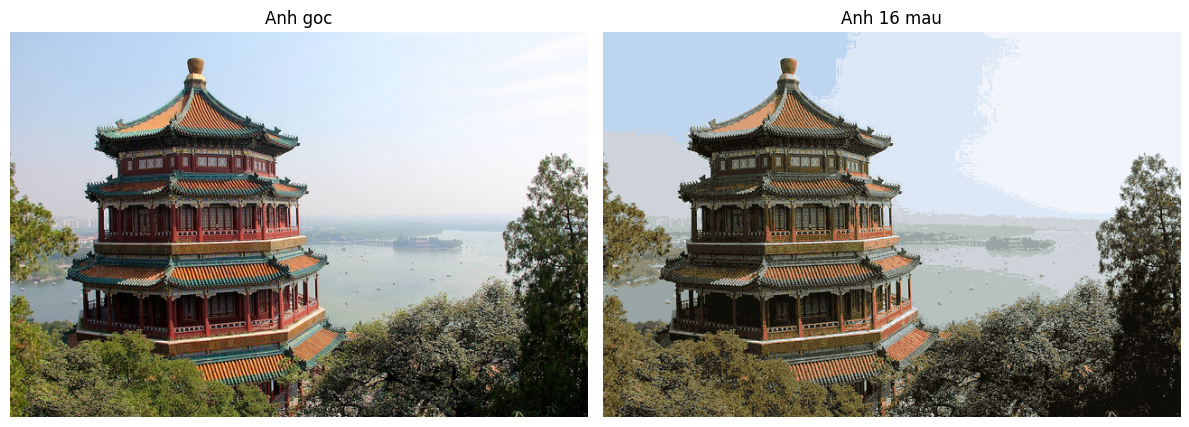


Khong co anh rieng, bo qua phan nen anh ca nhan.


In [17]:
#bài 4
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image
# Nap anh china.jpg co san trong scikit-learn
anh_goc = load_sample_image("china.jpg")
print("Kich thuoc anh goc:", anh_goc.shape)
chieu_cao, chieu_rong, so_kenh = anh_goc.shape
# Chuyen anh thanh cac diem anh RGB
X = anh_goc.reshape(-1, 3).astype(float) / 255.0
# Lay ngau nhien 5000 diem anh de huan luyen
rng = np.random.default_rng(0)
chi_so_mau = rng.choice(len(X), size=5000, replace=False)
X_mau = X[chi_so_mau]
# Tao mo hinh K-Means voi 16 mau
kmeans = KMeans(n_clusters=16, n_init=4, random_state=0)
kmeans.fit(X_mau)
# Gan moi diem anh vao mau gan nhat
nhan_mau = kmeans.predict(X)
# Thay moi diem anh bang mau tam cum
anh_moi = kmeans.cluster_centers_[nhan_mau]
# Dua anh ve kich thuoc ban dau
anh_moi = anh_moi.reshape( chieu_cao, chieu_rong, 3)
# Luu anh goc va anh sau khi nen
plt.imsave("anh_goc.png", anh_goc)
plt.imsave("anh_16_mau.png", anh_moi)
# Tinh dung luong hai tep
dung_luong_goc = os.path.getsize("anh_goc.png")
dung_luong_nen = os.path.getsize("anh_16_mau.png")
print("\nDung luong anh goc:", dung_luong_goc, "bytes")
print("Dung luong anh 16 mau:", dung_luong_nen, "bytes")
# Hien thi anh truoc va sau khi nen
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(anh_goc)
plt.title("Anh goc")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(anh_moi)
plt.title("Anh 16 mau")
plt.axis("off")
plt.tight_layout()
plt.show()
# Neu co anh rieng trong thu muc data thi nen them
duong_dan_anh_rieng = "data/anh_cua_em.png"
if os.path.exists(duong_dan_anh_rieng):
    anh_rieng = plt.imread(duong_dan_anh_rieng)
    # Bo kenh trong suot neu anh co dang RGBA
    if anh_rieng.ndim == 3 and anh_rieng.shape[2] == 4:
        anh_rieng = anh_rieng[:, :, :3]
    # Chuyen anh xam thanh 3 kenh neu can
    if anh_rieng.ndim == 2:
        anh_rieng = np.stack([anh_rieng, anh_rieng, anh_rieng], axis=-1)
    # Dua pixel ve khoang 0 den 1
    anh_rieng = anh_rieng.astype(float)
    if anh_rieng.max() > 1:
        anh_rieng = anh_rieng / 255.0
    chieu_cao_rieng, chieu_rong_rieng, _ = anh_rieng.shape
    X_rieng = anh_rieng.reshape(-1, 3)
    so_mau_huan_luyen = min(5000, len(X_rieng))
    chi_so_rieng = rng.choice(len(X_rieng), size=so_mau_huan_luyen, replace=False)
    kmeans_rieng = KMeans( n_clusters=16, n_init=4, random_state=0)
    kmeans_rieng.fit(X_rieng[chi_so_rieng])
    nhan_rieng = kmeans_rieng.predict(X_rieng)
    anh_rieng_moi = kmeans_rieng.cluster_centers_[nhan_rieng]
    anh_rieng_moi = anh_rieng_moi.reshape(chieu_cao_rieng, chieu_rong_rieng, 3)
    plt.imsave("anh_rieng_16_mau.png", anh_rieng_moi)
    print("\nDa luu anh rieng sau khi nen.")

else:
    print("\nKhong co anh rieng, bo qua phan nen anh ca nhan.")

Nhận xét:
- Ảnh gốc được lấy từ thư viện scikit-learn, có kích thước (427, 640, 3).
- Mỗi điểm ảnh được biểu diễn bởi ba giá trị màu RGB.
- K-Means gom các điểm ảnh thành 16 cụm màu. Mỗi điểm ảnh được thay bằng màu tâm của cụm tương ứng.
- Ảnh sau khi nén vẫn giữ được nội dung chính nhưng màu sắc có thể thay đổi so với ảnh ban đầu.
- Chương trình lưu ảnh gốc và ảnh sau khi nén thành hai tệp riêng biệt, sau đó so sánh dung lượng để đánh giá kết quả.

In [18]:
#bài 5
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]].to_numpy(dtype=float)
nhan_that = df["nhan"].to_numpy()
# Chay DBSCAN voi cac gia tri eps
cac_gia_tri_eps = [0.2, 0.3, 0.4]
for eps in cac_gia_tri_eps:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    nhan_dbscan = dbscan.fit_predict(X)
    # Bo nhan -1 vi day la diem nhieu
    cac_cum = set(nhan_dbscan)
    cac_cum.discard(-1)
    so_cum = len(cac_cum)
    so_diem_nhieu = np.sum(nhan_dbscan == -1)
    print("\neps =", eps)
    print("So cum:", so_cum)
    print("So diem nhieu:", so_diem_nhieu)
# So sanh voi K-Means
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan_kmeans = kmeans.fit_predict(X)
# Thu hai cach gan nhan vi thu tu cum co the bi dao
ti_le_khop_1 = np.mean(nhan_kmeans == nhan_that)
ti_le_khop_2 = np.mean((1 - nhan_kmeans) == nhan_that)
ti_le_khop = max(ti_le_khop_1, ti_le_khop_2)
print("\nTy le khop nhan that cua K-Means:", round(ti_le_khop, 4))


eps = 0.2
So cum: 1
So diem nhieu: 40

eps = 0.3
So cum: 1
So diem nhieu: 10

eps = 0.4
So cum: 1
So diem nhieu: 3

Ty le khop nhan that cua K-Means: 0.75


Nhận xét:
- DBSCAN phân cụm dựa trên mật độ của các điểm dữ liệu, không cần xác định trước số cụm.
- eps là bán kính xác định phạm vi lân cận của một điểm. Khi eps tăng, nhiều điểm có thể kết nối với nhau hơn.
- Với eps = 0.2, có 40 điểm bị xem là nhiễu. Khi tăng lên 0.3, số điểm nhiễu giảm còn 10; đến 0.4 chỉ còn 3 điểm nhiễu.
- Tuy nhiên, cả ba giá trị eps đều chỉ tìm được một cụm, nên DBSCAN chưa tách được hai vầng trăng thành hai nhóm riêng biệt.
- K-Means chia dữ liệu dựa trên khoảng cách đến tâm cụm nên không phù hợp hoàn toàn với những cụm có hình dạng cong như hai vầng trăng.
- Trong thí nghiệm này, DBSCAN với các giá trị eps đã thử chưa cho kết quả phân tách tốt hơn K-Means.

In [20]:
#bài 6
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
# Tai du lieu chu so viet tay
digits = load_digits()
X = digits.data
nhan_that = digits.target
# Tao mo hinh K-Means voi K = 10
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
# Phan cum khong su dung nhan that
cum = kmeans.fit_predict(X)
# Lap bang cheo sau khi phan cum
bang_cheo = pd.crosstab(
    nhan_that,
    cum,
    rownames=["Nhan that"],
    colnames=["Cum"])
print("Bang doi chieu nhan that va cum:")
print(bang_cheo)
# Tim cum co nhieu mau nhat cua tung chu so
print("\nCum chua nhieu mau nhat cua tung chu so:")
for chu_so in range(10):
    so_luong = bang_cheo.loc[chu_so]
    cum_nhieu_nhat = so_luong.idxmax()
    so_mau = so_luong.max()
    tong_mau = so_luong.sum()
    ti_le = so_mau / tong_mau * 100
    print(f"Chu so {chu_so}: "f"Cum {cum_nhieu_nhat}, "f"{so_mau}/{tong_mau} mau, "f"chiem {ti_le:.2f}%")

Bang doi chieu nhan that va cum:
Cum          0    1    2   3    4    5    6    7    8    9
Nhan that                                                 
0          176    0    0   0    0    0    2    0    0    0
1            0  100    0  54    1    2    0    1    0   24
2            1    8    3   2   13    0    0    0    2  148
3            0    7    7   0  154    0    0    2   13    0
4            0    2   11   3    0    0  165    0    0    0
5            0    0    0   0    2    1    2  136   41    0
6            1    3    0   0    0  177    0    0    0    0
7            0    2  174   2    0    0    0    1    0    0
8            0  100    5   6    2    2    0    4   52    3
9            0    1    8  20    6    0    0    6  139    0

Cum chua nhieu mau nhat cua tung chu so:
Chu so 0: Cum 0, 176/178 mau, chiem 98.88%
Chu so 1: Cum 1, 100/182 mau, chiem 54.95%
Chu so 2: Cum 9, 148/177 mau, chiem 83.62%
Chu so 3: Cum 4, 154/183 mau, chiem 84.15%
Chu so 4: Cum 6, 165/181 mau, chiem 91.16%
Ch

Nhận xét:
- K-Means chia dữ liệu chữ số viết tay thành 10 cụm mà không sử dụng nhãn thật trong quá trình phân cụm.
- Sau khi phân cụm, bảng chéo được sử dụng để so sánh kết quả phân cụm với nhãn thật.
- Chữ số 0 được gom khá tốt vào cụm 0 với 176/178 mẫu. Chữ số 6 được gom vào cụm 5 với 177/181 mẫu. Chữ số 7 được gom vào cụm 2 với 174/180 mẫu.
- Chữ số 1 và chữ số 8 cùng có nhiều mẫu trong cụm 1. Chữ số 5 và chữ số 9 cũng có một phần mẫu cùng xuất hiện trong cụm 8.
- Điều này cho thấy một số chữ số có đặc điểm hình ảnh tương tự nhau nên K-Means chưa phân biệt hoàn toàn rõ ràng.